# WP12 — Gerçek S07: teknik geçiş ve kaynak/dil incelemesi

Bu notebook yalnız kayıtlı cevabı inceler. Yeni API, model/optimizer veya otomatik tekrar yoktur. **HTTP200/şema PASS, tam Türkçe/semantik onay değildir.** S07 kalite notları ayrı, insan kararı PENDING; S04 kilitli kalır.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

Q=ROOT/'reports/qa/WP12/openai_S07_actual_review_v1'
F=ROOT/'reports/figures/WP12/openai_S07_actual_review_v1'
r=json.loads((Q/'independent_review.json').read_text(encoding='utf-8'))
display(pd.DataFrame([{'model':r['model'],'HTTP':r['HTTP_status'],'completion':r['completion_status'],
    'request_ID':r['API_request_id'],'süre_s':r['latency_HTTP_seconds'],'insan':'PENDING'}]))
print('Modelin birebir JSON mesajı:\n'+(Q/'exact_model_message.txt').read_text(encoding='utf-8'))


Modelin birebir JSON mesajı:
{"result":{"schema_version":"WP12-local-llm-candidate-v2","status":"candidate","refusal_code":null,"language":"tr","items":[{"explanation_tr":"Bu başlık, tetracyclines sınıfı için renal toksisite bağlamını verir: BUN artışı bildirilmiştir ve bunun dozla ilişkili olabileceği söylenir. Bu ifade sınıf düzeyindedir; tek başına doxycycline için bağımsız doğrudan kanıt olarak okunmamalıdır.","source_scope":"class_level","statement_kind":"adverse_context","evidence_ids":["quote:9882fd3b194817596c0e2b90da5ab49b7b708ce9db09fe072566f2948593d787","quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48","quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b"]},{"explanation_tr":"Sınıf girişine göre sonraki advers reaksiyonlar tetracyclines alan hastalarda gözlenmiştir; bu, alt başlıktaki renal ifadenin sınıf bağlamında anlaşılması gerektiğini gösterir. Bu nedenle kayıt, tetracycline sınıfını doğrudan doxycycline'e eşitlemeden okunmalıdı

,model,HTTP,completion,request_ID,süre_s,insan
0,gpt-5.4-mini-2026-03-17,200,completed,req_f009fc73d6dc4ff1ada8a9d8c27fe707,4.813,PENDING


**Yorum:** Tamamlanmış tek S07 yanıtı üç item içerir. Düzeltme yapılmadan gösterilir; bu metin üzerinde ikinci inference veya en iyi yanıt seçimi yoktur. Aşağıdaki notlar bu run'a bağlı **ajan okumasıdır**, genel semantik classifier veya kullanıcı insan kararı değildir.

## 1. Kaynaklar ve gerçek cümleler

,item,physical_page,scope,kind,primary_quote_exact,model_explanation_exact,all_cited_ids,agent_note_tr,human_decision
0,1,7,class_level,adverse_context,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,"Bu başlık, tetracyclines sınıfı için renal toksisite bağlamını verir: BUN artışı bildirilmiştir ve bunun dozla ilişkili olabileceği söylenir. Bu ifade sınıf düzeyindedir; tek başına doxycycline için bağımsız doğrudan kanıt olarak okunmamalıdır.","[""quote:9882fd3b194817596c0e2b90da5ab49b7b708ce9db09fe072566f2948593d787"", ""quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48"", ""quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b""]",tetracyclines sınıf adı İngilizce bırakılmış. BUN bildirimi ve dozla ilişkili olabileceği ifadesi sınıf kapsamında; doğrudan doxycycline kanıtı olmadığı belirtilmiş.,PENDING
1,2,7,class_level,scope_anchor,The following adverse reactions have been observed in patients receiving tetracyclines. \n,"Sınıf girişine göre sonraki advers reaksiyonlar tetracyclines alan hastalarda gözlenmiştir; bu, alt başlıktaki renal ifadenin sınıf bağlamında anlaşılması gerektiğini gösterir. Bu nedenle kayıt, tetracycline sınıfını doğrudan doxycycline'e eşitlemeden okunmalıdır.","[""quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48""]","İlk sınıf gözlemi doğrudan alıntıyla destekli. Renal alt başlık/doxycycline yorumu tüm girdi bağlamında destekleniyor; yalnız cite edilen sınıf-giriş cümlesi bu sözcükleri içermiyor. Bu, mevcut teknik kuralı değiştiren bir FAIL değildir; item düzeyinde atıf ayrıntısı için ajan inceleme notudur.",PENDING
2,3,4,class_statement_with_doxycycline_exception,warning,The antianabolic action of the tetracyclines may cause an increase in BUN. Studies to date indicate that this does not occur \nwith the use of doxycycline in patients with impaired renal function. \n,"Tetracyclines’in antianabolik etkisi BUN artışına yol açabilir. Mevcut çalışmalara göre bu durum, impaired renal function olan hastalarda doxycycline kullanımıyla ortaya çıkmamıştır.","[""quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b""]",May cause → yol açabilir; studies to date indicate → mevcut çalışmalara göre; doxycycline ve renal koşul korunmuş. Ancak impaired renal function çevrilmeden kalmış; tetracyclines de İngilizce. Tam Türkçe açıklama gereksinimi tam karşılanmıyor. Yeni klinik negatif/evrensel güvenlik iddiası gözlenmedi.,PENDING


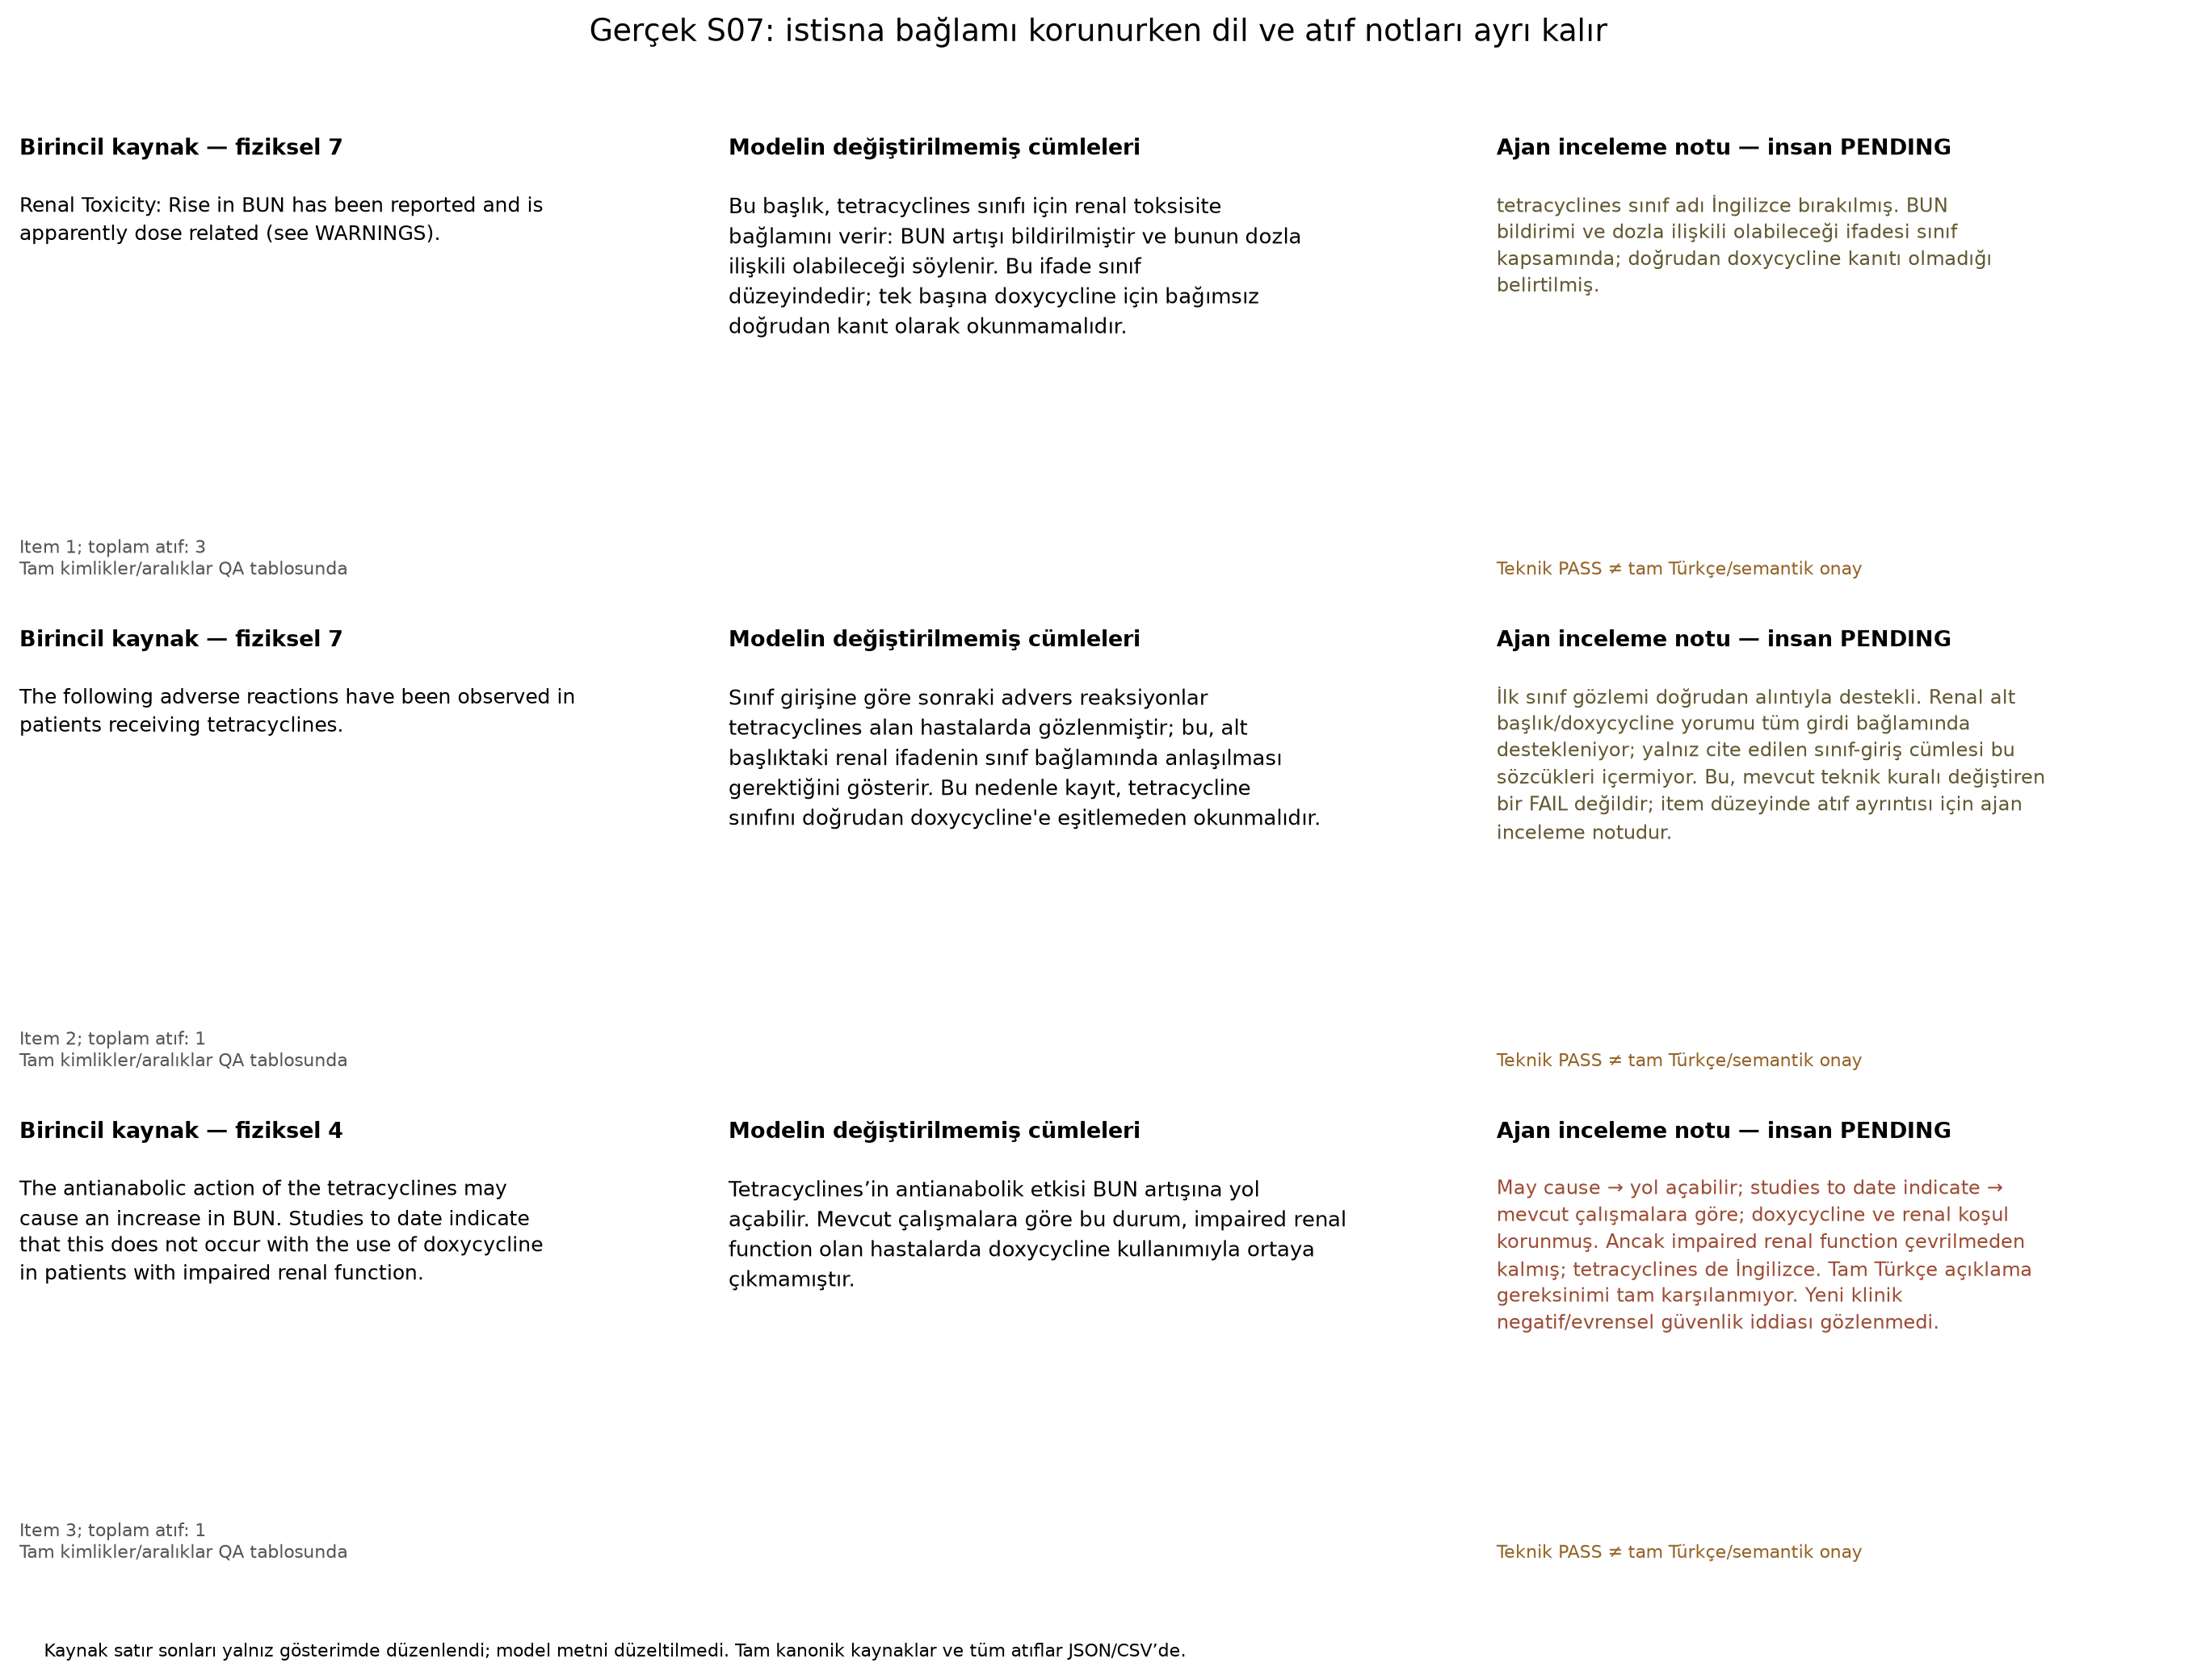

In [2]:

table=pd.read_csv(Q/'source_claim_comparison.csv')
with pd.option_context('display.max_colwidth',None):
    display(table[['item','physical_page','scope','kind','primary_quote_exact','model_explanation_exact','all_cited_ids','agent_note_tr','human_decision']])
from IPython.display import Image
display(Image(filename=str(F/'01_real_quotes_claims_and_flags.png')))


**Kaynak yorumu:** BUN bildirimi sınıf kapsamında tutulmuş; “dozla ilişkili olabileceği” belirsizliği ve doxycycline için bağımsız doğrudan kanıt olmadığı açıklanmış. İstisna item'ında “yol açabilir” ile “Mevcut çalışmalara göre” ve renal koşul mevcut. Koşulsuz güvenlik veya yeni klinik negatif etiketi gözlenmedi.

**Dil kalite notu:** “impaired renal function” aynen İngilizce bırakılmış; kullanıcıya tam Türkçe açıklama gereksinimi tam karşılanmıyor. “tetracyclines” sınıf sözcüğü de İngilizce. “böbrek işlevi bozulmuş” yalnız ajan açıklama notudur; modelin metnine yazılmamıştır. Kaynak koşulunun var olması Türkçe anlatım kalitesini otomatik PASS yapmaz.

## 2. Gerçek atıf kapsamı

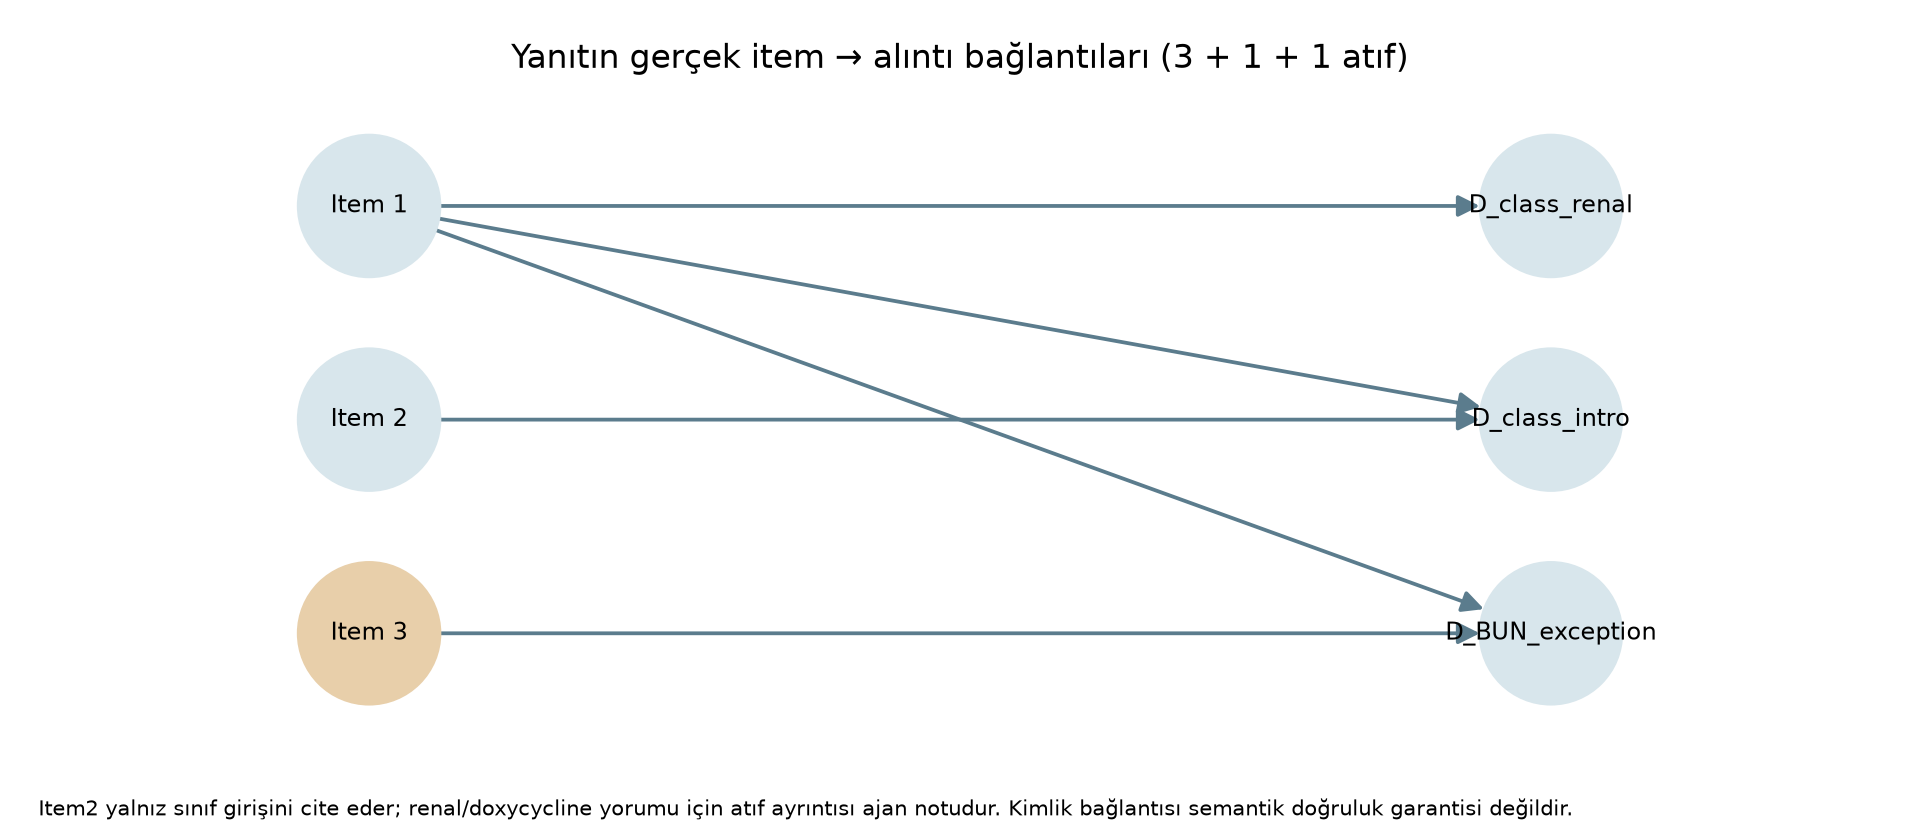

,item,text_exact,char_start,char_end,agent_explanatory_gloss_tr,gloss_is_not_modified_LLM_output,status,not_a_general_language_classifier
0,3,impaired renal function,98,121,böbrek işlevi bozulmuş,True,UNTRANSLATED_CLINICAL_CONDITION,True


In [3]:

display(Image(filename=str(F/'02_real_citation_network.png')))
display(pd.DataFrame([json.loads((Q/'untranslated_span_agent_note.json').read_text(encoding='utf-8'))]))


**Atıf yorumu:** Item2'deki sınıf gözlemi doğrudan sınıf girişinden desteklenir. “Renal alt başlık” ve doxycycline karşılaştırması tüm girdi bağlamında açıklanabilir; ancak yalnız cite edilen sınıf-giriş cümlesi bu sözcükleri içermez. Item düzeyinde atıf ayrıntısı inceleme notudur. Mevcut şema/başarı ölçütü sonradan değiştirilmedi; teknik PASS geriye dönük FAIL yapılmadı. Doğru kimlik ile iddianın kaynak kapsamı ayrı değerlendirilir.

## 3. Gerçek token/maliyet ve korunan sayaçlar

,input,cached,output,reasoning_in_output,total,input_USD,output_USD,S07_USD
0,1962,0,504,0,2466,0.0014715,0.002268,0.0037395


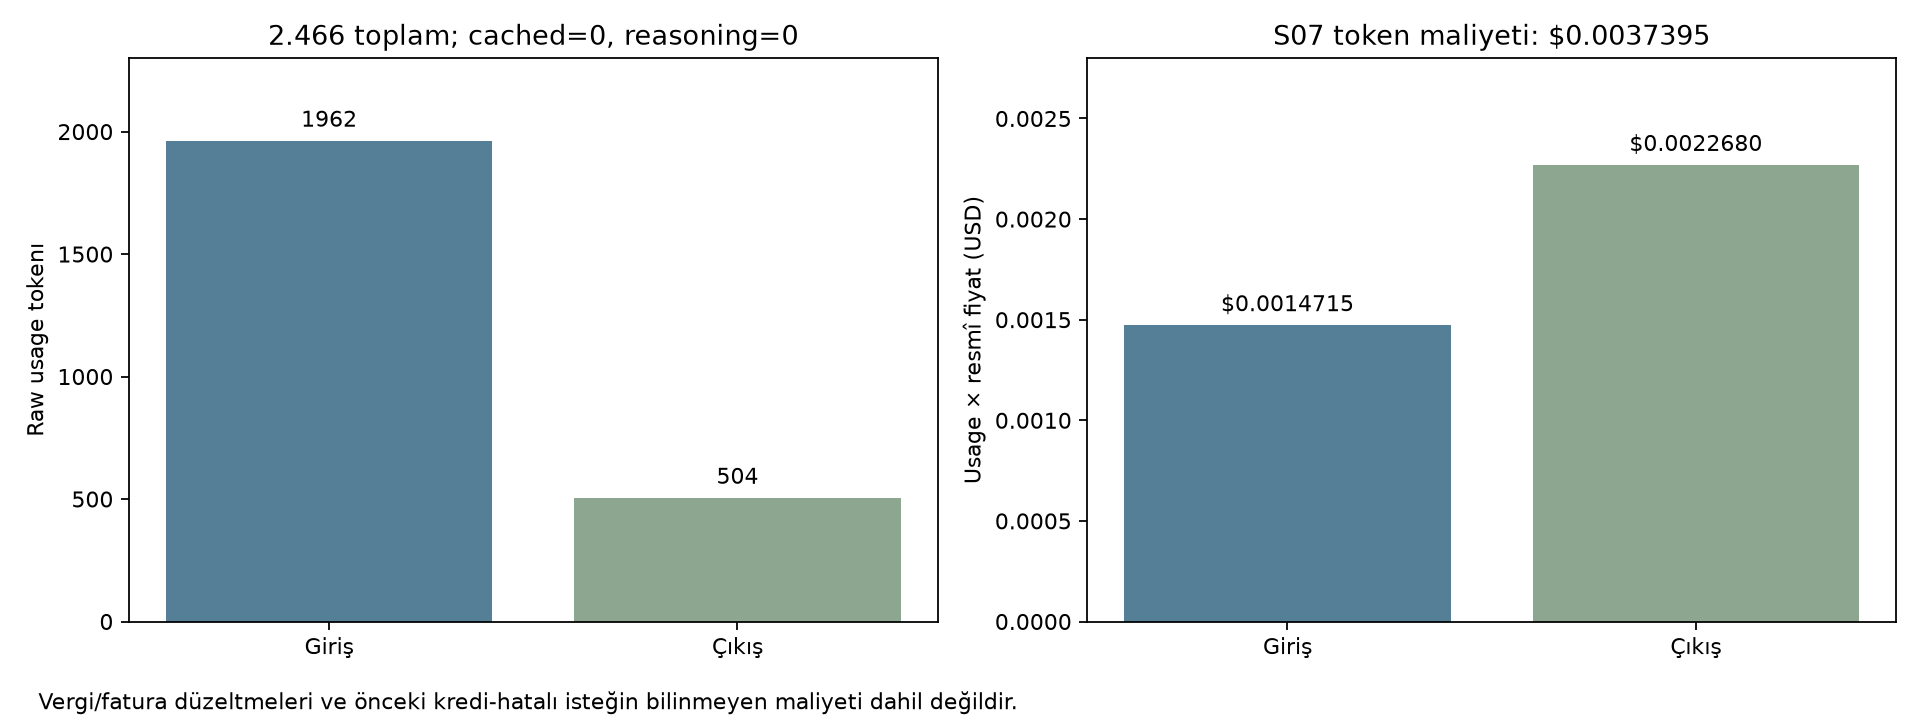

,HTTP_reservations_total,inference_reservations_total,reserved_USD,within_limits,unknown_prior_cost_not_refunded,actual_invoice_total
0,9,3,0.069,True,True,UNKNOWN_NOT_QUERIED


In [4]:

u=r['usage']
display(pd.DataFrame([{'input':u['input_tokens'],'cached':u['input_tokens_details']['cached_tokens'],
 'output':u['output_tokens'],'reasoning_in_output':u['output_tokens_details']['reasoning_tokens'],'total':u['total_tokens'],
 'input_USD':r['input_cost_USD'],'output_USD':r['output_cost_USD'],'S07_USD':r['usage_token_cost_USD']}]))
display(Image(filename=str(F/'03_actual_usage_and_cost.png')))
display(pd.DataFrame([r['aggregate_budget']]))


**Yorum:**1962×$0,75/1M +504×$4,50/1M =$0,0037395. Gerçek cached ve reasoning alanları0; çıkış tokenına ikinci ücret eklenmedi. Ücret vergi/fatura düzeltmeleri hariç usage-token hesabıdır. S01+S07 bilinen completed token maliyeti$0,0056430; ilk429 usage'ı ve toplam fatura UNKNOWN kalır.9HTTP/3inference rezervi$0,069; eski kayıtlar sıfırlanmadı.4,813s HTTP süresi ağ/servis toplamıdır; tek örnekten hız/kararlılık/genelleme iddiası yoktur.

## 4. QA, geçmiş koşular ve insan kararı

In [5]:

display(pd.DataFrame([{'kontrol':k,'sonuç':v} for k,v in r['checks'].items()]))
display(pd.DataFrame([json.loads((Q/'test_summary.json').read_text(encoding='utf-8'))]))
c=pd.read_csv(Q/'all_real_runs_and_locked_S04.csv')
display(c[['scenario','model_method','experiment_status','actual_language_agent','source_faithfulness_agent','human_review']])
display(pd.DataFrame([{'alan':k,'durum':r[k]} for k in ['schema_status','application_status','source_core_agent','Turkish_quality_agent','citation_granularity_agent','human_review']]))


,kontrol,sonuç
0,raw_run_hashes_match,True
1,run_inventory_matches_manifest,True
2,raw_response_hash_matches_record,True
3,request_and_source_equal_frozen_S07,True
4,prompt_components_and_execution_scope_hash_match,True
5,raw_JSON_matches_validated_and_independent_assessment,True
6,schema_and_source_application_pass,True
7,expected_completed_model,True
8,three_HTTP_200_single_inference,True
9,raw_PDF_identity_and_page_count,True


,tests,returncode,new_API_requests
0,14,0,0


,scenario,model_method,experiment_status,actual_language_agent,source_faithfulness_agent,human_review
0,S01,Gemma V1,FAIL,FAIL_ENGLISH,FAIL_CONTRADICTED,PENDING
1,S01,Gemma V2,FAIL,FAIL_ENGLISH,CORE_SUPPORTED_OMISSIONS,PENDING
2,S01,Qwen3 4B,NOT_RUN,NOT_RUN,NOT_RUN,PENDING
3,S01,OpenAI / first account,API_BILLING_BLOCKED_NO_MODEL_OUTPUT,NOT_EVALUABLE,NOT_EVALUABLE,PENDING_NO_OUTPUT
4,S01,gpt-5.4-mini-2026-03-17 / corrected account,COMPLETED_PENDING_HUMAN,TURKISH_SUPPORTED_SOURCE_PROPER_NAMES_RETAINED,SUPPORTED_FOR_TWO_RETURNED_ITEMS,PENDING
5,S07,gpt-5.4-mini-2026-03-17,COMPLETED_WITH_AGENT_QUALITY_FLAGS,NOT_FULL_PASS_UNTRANSLATED_CRITICAL_CONDITION,CLASS_SCOPE_AND_BOTH_EXCEPTION_CLAUSES_RETAINED_WITH_NOTES,PENDING
6,S04,gpt-5.4-mini / planned,LOCKED_NOT_RUN,NOT_RUN,NOT_RUN,PENDING


,alan,durum
0,schema_status,PASS
1,application_status,PASS
2,source_core_agent,CLASS_SCOPE_AND_BOTH_EXCEPTION_CLAUSES_RETAINED_WITH_NOTES
3,Turkish_quality_agent,NOT_FULL_PASS_UNTRANSLATED_CRITICAL_CONDITION
4,citation_granularity_agent,ITEM2_CONTEXT_REFERENCE_REVIEW_NOTE_NOT_SCHEMA_FAILURE
5,human_review,PENDING


**Durma kararı:** Teknik kontroller geçti; dilde somut eksik ve atıf ayrıntısı notu nedeniyle koşulsuz kalite PASS verilmedi. İnsan karar formu PENDING. S01 olumlu kullanıcı beyanı ayrı kalır; S01/S07 resmî insan QA kaydı otomatik değiştirilmez. Kaynak PDF/senaryo/şema/prompt/istemci dondurulmuş; başarısız eski kayıtlar ve Qwen NOT_RUN korunmuştur. S04 hâlâ LOCKED_NOT_RUN. Yeni yöntem/yeniden deneme,19×3, yayın, eğitim ve WP13 yoktur. Sonuç kullanıcı incelemesine sunulur.

[Resmî model/fiyat](https://developers.openai.com/api/docs/models/gpt-5.4-mini); kullanıcı PDF'si050641Orig1s032lbl.pdf fiziksel4/7. Tam kaynak sayfaları bu raporun figür klasöründe görsel olarak incelenmiştir.